## Pegasus Evaluation: Setup and Base Case

The evaluation of the paper (Section V), split into `2a_base_case.ipynb` (A, B.1), `2b_evidence.ipynb` (B.2, B.2b), `2c_depth_and_load.ipynb` (B.3, B.4), `2d_tails_and_percentiles.ipynb` (B.5, B.6) and `2e_iterative.ipynb` (C.1, C.2). This notebook holds the setup (Section A) and the base case B.1 on every chain of the campaign; the other experiments of Section B on the coverage and the tightness of the bounds (B.2 to B.6) and the
iterative use of the bounds in Section C are in the notebooks named above. This notebook needs real data: with
synthetic data it only sets up the parameters, because B.1 on All Chains runs on real data only (its section says why). Every experiment runs on one of two data sources, chosen with `data_source` in the first code cell:

- **synthetic**: generated service types (`pegasus/data.py`) and the simulator of a chain of queues
  (`pegasus/simulation.py`). A chain never repeats a service type: a seeded generator provides as many different
  service types as the chain is deep.
- **real**: the second testbed campaign in `statics/results_milos_v2/`, read by `pegasus/real_data.py`: the chains in
  `b1/` (the B1 experiments of `new_experiments.md`) and a benchmark of every service alone in `benchmark/`.

**How the real data is used.** Every service of the second campaign takes its items in the order of arrival and
processes each with its one worker, under Poisson arrivals at a rate that the campaign set for every run. The
latencies that the campaign measured are therefore the ground truth as they are; nothing is emulated. B.1 evaluates
every chain of the campaign; B.2 to B.6 build on one of them, `b1-vision-1-single` (an object detector, an image
transformer and an image compressor with one worker each).

**Unseen compositions.** Every service is trained on its benchmark: the service alone, at ten configurations, each
measured at the utilizations 0.1, 0.4, 0.6, 0.8 and 1.0. No run of any chain trains a model, so every chain is an
unseen composition, as in the setting of the paper: a service is characterized once, alone, and then composed into
any chain. The held-out configurations of a chain are all its runs without throttling (below), the same under every
seed; a seed draws the training runs of every service from its benchmark.

**Only runs without throttling.** Docker enforces the cores of a service as a quota of CPU time per scheduling period
(100 ms by default); a container that has used up its quota stands still until the next period begins (*throttling*;
`throttled_fraction` in `dataset.csv` is the share of the periods of a run in which that happened). An item that is
processed during throttling waits for the next period, a delay that depends on the load and that the execution-time
model of the bounds does not contain. Only the runs in which no service was throttled are therefore used, as training
runs and as held-out runs (`unthrottled_runs` in `pegasus/real_data.py`); the other runs are neither trained on nor held
out. The evaluation thus covers configurations whose CPU quota suffices for their load. The benchmark gave every
service enough cores for its load (the CPU need from a probe times a slack), so almost none of its runs is throttled.

**The cores are no configuration.** A run that is used had enough cores for its load, and with enough cores the
execution time does not depend on them, so no model receives the cores (`NOT_CONFIGURATION` in
`pegasus/real_data.py`). In the benchmark the cores would even leak the execution time, because the campaign set them
from the CPU need of the configuration.

**Experiments that the real data does not support** run on synthetic data instead (`skipped` in `pegasus/evaluation_setup.py`): `2c_depth_and_load.ipynb` uses
synthetic data throughout, and C.2 the synthetic base case of B.1. They are B.3, whose fork-join trees the campaign has not measured yet; B.4a and B.4b,
because the campaign fixed the Poisson arrival rate of every run, so neither the load nor the arrival pattern can be
changed; C.2, because it
evaluates every run at one common arrival rate. B.2b is deactivated for both data sources (`run_b2b` in `2b_evidence.ipynb`). The section of each says the same.

Limits of the real data that hold for every experiment:

- The arrival rate of a run was chosen by the campaign from a short probe, so that the slowest service of the run is
  busy about half of the time; it is therefore not independent of the execution times.
- The bounds assume execution times that do not depend on the load. Throttling is excluded (above), but the services still share the CPUs of the host;
  `explain_9_does_provisioning_make_execution_times_load_independent.ipynb` tests how far the execution times of the
  second campaign depend on the load.
- A run measured a few hundred to a few thousand requests, so a measured latency quantile far in the tail rests on few
  requests; the confidence interval of every measured quantile accounts for this (`coverage_check`).

In [1]:
# Data source of every experiment:
# - "synthetic": generated services and a simulated chain of queues (pegasus/data.py, pegasus/simulation.py)
# - "real": the measured runs of the second testbed campaign in statics/results_milos_v2 (pegasus/real_data.py)
data_source = "real"

# the parameters and helpers that every evaluation notebook shares, defined once in pegasus/evaluation_setup.py
from pegasus.evaluation_setup import *
from pegasus.figures import math_label
p_label = math_label(p_label)   # the quantile name in the math notation of the paper, e.g. $P_{95}$, for the figures and the text
globals().update(configure(data_source))

## A. Experimental Setup

### Services and Chains

- **Synthetic:** `synthetic_service` in `pegasus/data.py` generates every service type from the seed
  `service_seed`: an execution-time function and a noise level with randomly drawn parameters. A chain of depth $|S|$
  consists of the first $|S|$ service types (`synthetic_chain`), so no service type occurs twice in a chain. All services
  of a chain share one configuration (CPU, quality, parallelism); the parallelism is the number of workers of every
  service, and CPU is the CPU of one worker.
- **Real:** the chains of the second campaign (`statics/results_milos_v2/b1/`, named
  `b1-<application>-<instance>-single`): several instances each of three applications (audio, vision, lidar), chains
  of different length (B.1 on All Chains prints their number and length). Every service has one worker and the knobs
  of its application (the resolution or audio quality `data_quality`, and the model size where a service has one).
  B.2 to B.6 use one of these chains, `b1-vision-1-single`: an object detector, an image transformer and an image
  compressor, with the resolution and the model size of the object detector as knobs. A run of the campaign is one
  configuration of every service of the chain, drawn at random; a benchmark run is one configuration of one service.
  The cores are no configuration (see the introduction).

**The number of workers is no model input.** By assumption, the workers of a service set only how many items it
processes at the same time, not how long one item takes. No prediction model, of the proposed method or of a baseline,
receives the number of workers (`model_inputs` in `pegasus/data.py`); the bounds, the Allen-Cunneen formula and the
simulator get it from the configuration (`path_workers`).

### Sampling Strategies

- **Synthetic:** training and held-out configurations are drawn uniformly at random. Active learning and grid search
  are possible, but not implemented.
- **Real:** the campaign drew the configuration of every run at random. The training runs of a service are drawn at
  random from its benchmark runs (see the introduction); the held-out configurations are the unthrottled runs of the chain.

### Baselines

Every baseline is trained on data of each service on its own, like the proposed method; none sees a held-out run. All are in `pegasus/baselines.py`, and B.1 describes them (Methods).

- Execution-time model per service, summed, without queue (GP, DNN).
- Queueing formula per service, summed (GP Queue).
- Latency quantile per service with split budget, without and with a conformal step (Quantile Union, Conformal). These
  two need every service monitored alone under load. With synthetic data, the simulator provides such runs; with real
  data, they are the latencies that a training run measured at the service inside the chain.

## B. Coverage and Tightness of Service Bounds

### B.1 Base Case: Every Chain of the Campaign

B.1 evaluates every method on every chain of the campaign, each chain an unseen composition (B.1 on All Chains,
below). Before that, Setting and Definitions fixes what every experiment of B shares: the chain that B.2 to B.6 build
on, the training data, the metrics, the rule *validity before tightness* and the methods. B.2 to B.6 refer to these
as the definitions of B.1.

#### Setting and Definitions (Shared by B.1 to B.6)

- **Synthetic:** B.1 is not run (see B.1 on All Chains). B.2 to B.6 build on the chain $s_1 \to s_2 \to s_3$ of three
  generated service types.
- **Real:** every chain of the campaign. B.2 to B.6 build on one of them, the chain detector → transformer → compressor
  (`base_experiment`, `b1-vision-1-single`): an object detector, an image transformer and an image compressor, each
  with one worker. This chain with its held-out configurations and its per-service models for every seed is `b1_base`
  in `pegasus/evaluation_setup.py`, which the notebooks 2b to 2e load from `statics/evaluation_cache/`.
  `1_method_real.ipynb` derives the node bounds and the compositions step by step on this chain.

**Setting (synthetic data).** The chain $s_1 \to s_2 \to s_3$ with every service at the same configuration, at held-out configurations
drawn from the training range; no held-out configuration occurs in the training data of any model. The ground truth
is the measured $(1-\varepsilon)$ quantile of the end-to-end latency of the chain, with $\varepsilon$ = `alpha`. The
experiment is repeated for every seed in `seeds`: a seed determines the three generated service types, the training
data and the held-out configurations. Whether a method holds is judged per seed (see Validity before tightness).

**Setting (real data).** The held-out configurations are all unthrottled runs of the chain (see the introduction):
every run is one configuration of each service of the chain, at the Poisson arrival rate that the campaign set for
it. The ground truth is the $(1-\varepsilon)$ quantile of the end-to-end latencies that the run measured. The chain and
its held-out runs are the same under every seed; a seed determines the training runs.

**Dependence between services.** The execution time of an item at one service can depend on its execution time at
another service of the chain: a large item is slow everywhere. The two data sources differ in this.
- *Synthetic:* the execution times of an item at the different services are independent. The simulator draws the
  execution-time noise of every service on its own (`item_correlation` = 0 in `pegasus/data.py`), so an item that is
  slow at one service is not more likely to be slow at the next one. `1_method_synthetic.ipynb` sets a positive
  `item_correlation` instead, to show the compositions under dependence.
- *Real:* the measured requests keep any dependence between the services that the testbed had.

With both sources, the latencies of an item at consecutive services depend on each other through the queues. Pegasus
per node is valid for any dependence between the services. Pegasus SNC assumes that the execution times of an item
are independent between the services (see Methods): that holds for the synthetic data and is an assumption for the
real data, which the coverage of Pegasus SNC tests but cannot prove. This holds in every experiment of B.

**Training data (real data).** The training runs of every service are drawn at random from its benchmark runs (the
service alone); no run of a chain is used. A training run gives the service one training configuration, and two statistics of its measured
execution times as targets. The execution time is the processing time plus a constant *hop overhead*, the time the
testbed needs to hand a request to the service: one constant for the first service of a chain (requests from the load
generator) and one for every later service (requests from the service before it), both measured on the other chains
of the campaign (`1_method_real.ipynb`, Section 1a). It replaces the overhead of the training run itself, which in a
benchmark comes from the load generator also for a service that sits later in the chain. The two statistics:
- the *mean* of the run, in seconds. A model of the execution time is trained on these run means and not on one item
  per run: a run measured many items, and their mean is a far less noisy observation of the mean execution time than
  one item. The error of the predicted mean is what makes the queueing-based methods fail
  (`explain_5_what_allen_cunneen_inputs_cost.ipynb` measures this on the GP Queue baseline).
  The GP is fitted on the logarithm of the run means: the knobs of a real service multiply its processing time (a
  larger model at a higher resolution), and on the logarithm these effects add, which a GP with one
  length scale per knob can fit. The length scale of every GP on real data has a lower limit (`MIN_LENGTH_SCALE` in
  `pegasus/service_gp.py`, in standard deviations of a knob): without it, the hyperparameter search of some services
  ends at a length scale near zero, where the GP reproduces every training run and predicts the average of all runs
  everywhere else (`1_method_real.ipynb`, Section 3, shows the fitted models).
- the *spread* of the run, in seconds: (95th percentile − median of the processing time) ÷ 1.645, the standard
  deviation of a Gaussian with that median and 95th percentile. A second GP per service is trained on the logarithm of
  the spreads and predicts the standard deviation of single items, which one item per run would otherwise have told
  the model.

With these two models, the belief of Pegasus about a service is: the pessimistic mean is the predicted mean shifted up
by the GP's uncertainty about the mean of a new run (its uncertainty about the mean function and the scatter between
runs at the same configuration; on the logarithm, so the shift is relative to the mean), and the variance per item is
the square of the predicted spread. GP Sum, DNN Sum and
GP Queue use the predicted mean and the predicted spread. With synthetic data nothing changes: one execution time per
training configuration, and one GP for both.

For Quantile Union and Conformal, a service is monitored by the
latencies that its benchmark run measured, the service alone at the arrival rate of that run (utilization 0.1 to
1.0), with the hop overhead of its position in place of the overhead of the run, as for the targets above. Because
that rate differs between runs, the two baselines get the arrival rate as a further input. Their GPs are fitted on the logarithm of the latency quantile,
for the same reason as the GP of the mean execution time.

**Training data (synthetic data).** Every method is trained on data of each service on its own and never on a run of the chain. The
proposed method, the two execution-time baselines and the queueing formula use one execution time per service and training configuration.
Quantile Union and Conformal use the latencies (waiting plus execution) of each service monitored alone under the
arrival process of the workload, at the same training configurations.

**Metrics.** *Tightness* of a method at a configuration is its end-to-end latency ÷ the measured quantile: 1 is exact,
above 1 is looser, below 1 is under the measured quantile. *Coverage* is the share of configurations at which a method
is not below the lower edge of the confidence interval of the measured quantile (`coverage_check`).

*Training time* and *evaluation time* of a method, both in seconds on the machine that ran the notebook, are reported
in B.2 and B.3.
- The training time is the time to train the models that the method uses. Both versions of Pegasus, GP Sum and GP Queue
  use the same execution-time GPs, one per service, so these four methods have the same training time. Quantile Union
  and Conformal each train their own GPs of the latency quantile, one per service; for Conformal the calibration of the
  correction factor counts as training.
- The evaluation time is the time to compute the end-to-end latency at all held-out configurations of one seed from the
  trained models, including the predictions of these models.
- Neither time contains the collection of the training data: one execution time per service and training configuration
  for the four methods on execution-time GPs, and a run under load per service and training configuration for Quantile
  Union and Conformal.

**Validity before tightness.** This rule is the same in every experiment of B.
- A method *reaches the confidence level* under a seed if its coverage over the held-out configurations of that seed
  is at least `confidence`.
- A method *holds* in a setting if it reaches the confidence level under every seed in `seeds`. A setting is
  one chain in B.1 and one value of the varied quantity in B.2 to B.6, for example one number of training configurations in
  B.2 or one tree in B.3. The worst seed decides: a method with
  full coverage under all seeds but one that falls below `confidence` under the remaining seed does not hold, because
  a guarantee that depends on the drawn services and training data is not a guarantee.
- Every conclusion first names the methods that hold, and compares tightness only among those. The tightness of a
  method that does not hold describes a value that can lie below the measured quantile, not a bound.

**Methods.** The proposed method has two versions. Both use the same GP model of the execution time per service and
differ in how the services are composed. Both are evaluated in B.1 and B.3; every other experiment evaluates Pegasus
Node only (`PROPOSED_SNC` in its `leave_out`); `explain_3_how_pegasus_bounds_compose.ipynb` derives both and tests their strengths
and weaknesses.
- *Pegasus Node (ours):* the union bound over martingale node bounds in closed form. The waiting time at a service is
  bounded by Kingman's martingale bound, an exponential tail whose rate follows from the moment generating function of
  the service's execution time and from its arrivals; with a Gaussian execution time, the latency bound of the service
  is then one formula. Every service is bounded with the external arrivals, also a later service that receives the
  departures of the service before it. Every service is bounded
  at the violation probability $\varepsilon / |S|$ for a chain of $|S|$ services, and the $|S|$ bounds are added; this is valid
  for any dependence between the services.
- *Pegasus SNC (ours):* one bound for the whole chain from its network service curve (stochastic network calculus, SNC).
  The latency moments of the services (the moment generating function of the execution time ÷ (1 − utilization at that
  parameter θ)) are multiplied, and one Chernoff step on the product bounds the end-to-end latency at the full
  violation probability $\varepsilon$. Multiplying the moments requires independent services (see Dependence between
  services). No Hölder step is applied: it would make the bound valid for dependent services, at the price of a larger
  variance per service and of a longer evaluation, because its exponents are tuned iteratively for every configuration
  and every θ; `1_method_real.ipynb` (Section 7b) computes the bound with that step. Only the external arrivals enter this bound.
- *GP Sum, DNN Sum (baselines; execution-time model per service, summed, no queue):* the $(1-\varepsilon)$ quantile of the sum of the
  predicted execution times, with a GP and with a neural network (DNN) per service. Both are compared in B.1; B.2 to B.6
  keep GP Sum only (`only_base_case`), the faster of the two, because the GPs are trained for Pegasus and GP Queue anyway.
- *GP Queue (baseline; queueing formula per service, summed):* the GP's mean and variance of the execution time enter a textbook
  formula for one queue with the $c$ workers of the service (the Allen-Cunneen approximation of the mean waiting time
  of a G/G/c queue, which is Kingman's formula for $c = 1$, and an exponential waiting-time tail), which gives the
  $(1-\varepsilon)$ latency quantile of each service; the quantiles are added.
- *Quantile Union (baseline; latency quantile per service, split budget):* one GP per service predicts the
  $(1-\varepsilon/|S|)$ latency quantile of the service alone under load, for a chain of $|S|$ services; the predictions
  are added. This is the union bound applied to point predictions, trained on all training configurations.
  *Note:* the arrival rate is not an input of this model, so the model holds only for the workload its services were
  monitored under. With the arrival rate as an input (as in Fluxion), samples from existing executions at other loads
  could be reused for a new composition. The model would still not know that later services of a chain queue less:
  every service of a chain receives the same rate, and what changes is how evenly the arrivals are spaced.
- *Conformal (baseline; Quantile Union with a conformal step):* the same model, trained on the training
  configurations except `n_calibration` of them, on which a correction factor is calibrated (the ratio measured ÷
  predicted quantile). Every prediction is multiplied by that factor, so that it holds per service with probability
  `confidence`; the bounds of the services are added.
- *Oracle (reference):* the union bound over the measured latency quantiles of the services in the chain; it uses the ground
  truth and is not a competitor. With real data it reads them from the first requests of every run, as many as the
  shortest held-out run has.

#### B.1 on All Chains (Real Data Only)

- **Synthetic:** not run. Every synthetic service is already trained on its own, never on a run of the chain.
- **Real:** every chain of `statics/results_milos_v2/b1/` as an *unseen instance*: no run of the evaluated chain trains
  any model. The campaign has three applications (audio, vision, lidar) with five instances each, chains of three to six
  services (`b1-<application>-<instance>-single`); every service occurs in two or three instances of its application.
- **Baselines:** every baseline of Methods above, DNN Sum included. Both versions of the proposed method, Pegasus Node and Pegasus SNC, are evaluated.

**Training source.** Every service is trained on its benchmark, the runs of the service alone (see the introduction
and Training data above).

**Held-out runs and training runs.** The held-out configurations of a chain are all its unthrottled runs, and per seed `n_train` unthrottled training runs are drawn at random per service. That number is limited by the service with the fewest usable
benchmark runs (the code below prints the smallest benchmark): a benchmark run at utilization 1.0 in which no request
found the service idle has no measurable handling overhead and is left out (`training_pool` in `pegasus/real_data.py`).

**Model inputs.** The knobs of the application (the resolution or audio quality `data_quality`,
and the model size where a service has one), not the cores. Quantile Union and Conformal are monitored at the arrival
rate of the training run (the service alone at its benchmark utilization) and get log10 of that rate as a further input.

**Validity per chain.** A method *holds on a chain* if it reaches the confidence level (coverage ≥ `confidence`) on
the held-out runs of that chain under every seed, the rule *validity before tightness* applied per chain.

In [2]:
# B.1 on all chains: every chain of the second campaign as an unseen instance, every service trained on its benchmark (real data only)
if data_source != "real":
    print("B.1 on all chains skipped: real data only")
else:
    n_train = base_options["n_train"]   # training runs per service and seed (configure in pegasus/evaluation_setup.py)

    def compute():
        unseen = {}   # (chain, seed) -> held-out ground truth and the end-to-end latency (s) of every method per held-out run
        unseen_chains = sorted(path.name for path in CAMPAIGN_V2.iterdir() if path.is_dir())
        with warnings.catch_warnings():
            warnings.simplefilter("ignore", ConvergenceWarning)
            for chain in unseen_chains:
                for s in seeds:
                    data = load_chain_data("real", experiment=chain, level=1 - alpha, coverage_check=coverage_check, seed=[seed, s],
                                           n_train=n_train, training_campaign=BENCHMARKS_V2)
                    models = fit_services(data, data.x_train, data.y_train, model_seed=seed + s, confidence=confidence)
                    latencies, _ = compare_methods(data, models, data.x_train, data.monitored_latencies, alpha, confidence, n_calibration,
                                                   model_seed=seed + s, x_train_load=data.x_train_load)
                    unseen[(chain, s)] = SimpleNamespace(path=data.path, measured=data.measured, measured_low=data.measured_low,
                                                         latencies={name: latency for name, (_, latency) in latencies.items()})
        smallest_pool = min(len(unthrottled_pool(training_pool(service, campaign=BENCHMARKS_V2)))
                            for service in campaign_nodes(CAMPAIGN_V2)["service"].unique())
        return dict(unseen=unseen, unseen_chains=unseen_chains, smallest_pool=smallest_pool)

    globals().update(cached("b1_all_chains", data_source, compute, inputs=dict(n_train=n_train)))
    chain_depth = {chain: len(unseen[(chain, seeds[0])].path) for chain in unseen_chains}
    held_out = [len(unseen[(chain, seeds[0])].measured) for chain in unseen_chains]
    print(f"{len(unseen_chains)} chains of {min(chain_depth.values())} to {max(chain_depth.values())} services, {min(held_out)} to {max(held_out)} "
          f"held-out runs per chain ({sum(held_out)} in all), {len(seeds)} seeds, {n_train} training runs per service and seed; "
          f"smallest unthrottled benchmark of a service: {smallest_pool} runs")

b1_all_chains: results loaded from statics\evaluation_cache\b1_all_chains_real_aa675723a2cf5d5c.joblib
15 chains of 3 to 6 services, 75 to 106 held-out runs per chain (1413 in all), 3 seeds, 25 training runs per service and seed; smallest unthrottled benchmark of a service: 27 runs


**Figure** (also saved as `figures/tsc/b1_all_chains_benchmark.pdf` and `.jpg`). A dot plot. The horizontal axis
lists the chains, grouped by application (names below the instance numbers, groups separated by dark vertical lines) and,
within an application, sorted by the number of services; a tick gives the instance of the application. The chains are independent instances, so no line connects them: within the column of a chain,
every method has one dot, side by side, with its own color and marker. The order of the columns keeps the markers apart:
methods whose dots lie close together, such as GP Sum and DNN Sum, get columns far apart (`separated_order` in
`pegasus/figures.py`). The vertical axis is the
tightness of a method on a chain on a logarithmic scale: its end-to-end latency ÷ the measured quantile. A dot is the
median over the seeds of the per-seed median over the held-out runs, and the vertical bar through it reaches from the
smallest to the largest seed. The black line at 1× is the measured quantile; in the red area below it ("underestimated: SLO violated") a
method lies under the measured quantile, so a configuration chosen with it to meet a latency SLO would violate the SLO. A filled dot means that the method holds on that chain (it reaches the
confidence level under every seed), a hollow dot that it does not; a method has no dot on a chain where its latency is
infinite at half of the held-out runs or more under half of the seeds or more. Look at the hollow dots first: a method
is only useful where its dots are filled, and the sorting shows whether its misses cluster in longer chains. Then
compare the height of the filled dots within a chain; the closer to 1×, the tighter. The figure keeps the tightness range of every figure in B (`TIGHTNESS_RANGE` in `pegasus/evaluation.py`). The legend sits inside the plot
where it hides no dot or bar of the other methods (`legend_inside` in `pegasus/figures.py`); it may cover parts of
Conformal.

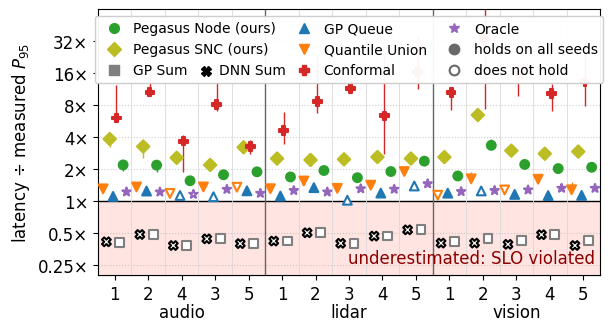

In [3]:
from pegasus.figures import FAILURE_COLOR, FAILURE_TEXT_COLOR, METHOD_STYLES, dodge_offsets, holds_handles, legend_entry_beside, legend_inside, method_handle, separated_order, paper_figure, paper_style, save_figure, tightness_label, tightness_tick


def unseen_holds(chain, name):
    # the method reaches the confidence level on the held-out runs of the chain under every seed
    return all(coverage(unseen[(chain, s)].latencies[name], unseen[(chain, s)].measured_low) >= confidence for s in seeds)


def unseen_tightness(chain, name):
    # median over the held-out runs of all seeds of latency / measured quantile (an infinite latency counts as infinitely loose)
    return np.median(np.concatenate([unseen[(chain, s)].latencies[name] / unseen[(chain, s)].measured for s in seeds]))


def seed_tightness(chain, name):
    # per seed the median over the held-out runs of latency / measured quantile; nan where that median is infinite
    medians = np.array([np.median(unseen[(chain, s)].latencies[name] / unseen[(chain, s)].measured) for s in seeds])
    return np.where(np.isfinite(medians), medians, np.nan)


if data_source == "real":
    unseen_names = list(unseen[(unseen_chains[0], seeds[0])].latencies)   # in the order of compare_methods
    application = lambda chain: chain.split("-")[1]
    applications = list(dict.fromkeys(application(chain) for chain in unseen_chains))   # in the order of the chains
    # the chains of an application by their number of services, so that the figure shows whether misses cluster in longer chains
    chain_order = sorted(unseen_chains, key=lambda chain: (applications.index(application(chain)), chain_depth[chain], chain))
    positions = np.arange(len(chain_order))
    seed_values = {name: np.array([seed_tightness(chain, name) for chain in chain_order]) for name in unseen_names}   # (chains, seeds)
    # median over the seeds, in which a seed without a finite value counts as infinitely loose, as in sweep_line
    typical_values = {name: np.median(np.where(np.isnan(values), np.inf, values), axis=1) for name, values in seed_values.items()}
    columns = dodge_offsets(len(unseen_names))   # one column per method within a chain
    with paper_style():
        fig, ax = paper_figure()
        # methods with similar values get columns far apart, so that their markers do not overlap: the distances of the
        # markers in pixels, a column being its share of the width of a chain and a doubling its share of TIGHTNESS_RANGE
        order = separated_order(typical_values, column_width=ax.bbox.width / len(chain_order) * (columns[1] - columns[0]),
                                doubling_height=ax.bbox.height / np.log2(TIGHTNESS_RANGE[1] / TIGHTNESS_RANGE[0]))
        offsets = dict(zip(order, columns))
        drawn = []   # (x, y_low, y_high) of every bar and dot, so that the legend can be placed where it hides none
        # below 1x the latency of a method is under the measured quantile: an SLO met with it is violated
        ax.axhspan(TIGHTNESS_RANGE[0], 1.0, color=FAILURE_COLOR, linewidth=0)
        ax.axhline(1.0, color="black", linewidth=1)
        # the chains are independent instances: no line connects them, every method is one dot per chain
        for name in unseen_names:
            color = METHOD_COLORS[name]
            values, typical = seed_values[name], typical_values[name]
            held = np.array([unseen_holds(chain, name) for chain in chain_order])
            shown, x = np.isfinite(typical), positions + offsets[name]
            ax.vlines(x[shown], np.nanmin(values[shown], axis=1), np.nanmax(values[shown], axis=1), color=color, linewidth=1)   # range over the seeds
            if name != "Conformal":   # the legend may cover parts of Conformal, so that the axis keeps TIGHTNESS_RANGE
                drawn += list(zip(x[shown], np.fmin(typical[shown], np.nanmin(values[shown], axis=1)), np.fmax(typical[shown], np.nanmax(values[shown], axis=1))))
            ax.scatter(x[shown], typical[shown], s=40, marker=METHOD_STYLES[name][0], linewidths=1.5, zorder=3, edgecolors=color,
                       facecolors=[color if h else "white" for h in held[shown]])
        for boundary in positions[1:] - 0.5:
            ax.axvline(boundary, color="0.85", linewidth=0.6)
        centers = []
        for k, app in enumerate(applications):
            chains_of_app = positions[[application(chain) == app for chain in chain_order]]
            if k > 0:
                ax.axvline(chains_of_app[0] - 0.5, color="0.4", linewidth=1)
            centers.append(chains_of_app.mean())
        # the application names below the instance numbers, in place of an axis label: the figure keeps the fixed layout of
        # every figure, and the top of the axes stays free for the legend
        names = ax.secondary_xaxis("bottom")
        names.set_xticks(centers, applications)
        names.tick_params(length=0, pad=20)
        ax.text(0.99, 0.03, "underestimated: SLO violated", transform=ax.transAxes, ha="right", va="bottom", color=FAILURE_TEXT_COLOR)
        ax.set_xticks(positions, [chain.split('-')[2] for chain in chain_order])
        ax.set_xlim(-0.5, len(chain_order) - 0.5)
        ax.set_yscale("log")
        ax.set_ylim(*TIGHTNESS_RANGE)
        ax.set_yticks(TIGHTNESS_TICKS, [tightness_tick(tick) for tick in TIGHTNESS_TICKS])
        ax.yaxis.set_minor_locator(plt.NullLocator())
        ax.set_ylabel(tightness_label(p_label))
        ax.grid(True, axis="y", linestyle=":", alpha=0.6)
        marker_handles, marker_labels = holds_handles()
        # DNN Sum sits in the row of GP Sum, in the space right of its short label, so that the legend keeps three rows
        legend_names = [name for name in unseen_names if name != "DNN Sum"]
        legend = legend_inside(ax, [method_handle(name, line=False) for name in legend_names] + marker_handles, legend_names + marker_labels, drawn,
                               max_doublings=0, ncol=3, fontsize=10, framealpha=0.95, columnspacing=1.0, handletextpad=0.4)
        legend_entry_beside(legend, "GP Sum", method_handle("DNN Sum", line=False), "DNN Sum")
        save_figure(fig, "b1_all_chains_benchmark")   # the name it had before, so that references to the file stay valid
        plt.show()

In [4]:
if data_source == "real":
    def pooled_tightness(name):
        # median over the held-out runs of all chains and seeds
        return np.median(np.concatenate([result.latencies[name] / result.measured for result in unseen.values()]))

    chains_held = {name: sum(unseen_holds(chain, name) for chain in unseen_chains) for name in unseen_names}
    everywhere = [name for name in unseen_names if name != "Oracle" and chains_held[name] == len(unseen_chains)]
    line = (f"- **Benchmark training.** Methods that hold on all {len(unseen_chains)} chains: "
            + (", ".join(f"{name} ({pooled_tightness(name):.2f}×)" for name in sorted(everywhere, key=pooled_tightness)) or "none")
            + " (in brackets the median tightness over all held-out runs). Chains held by the others: "
            + ", ".join(f"{name} {chains_held[name]}" for name in unseen_names if name not in everywhere) + ".")
    display(Markdown(f"**What this shows** (real data, {len(unseen_chains)} unseen chains, ε = {alpha:g}, {len(seeds)} seeds).\n" + line))

**What this shows** (real data, 15 unseen chains, ε = 0.05, 3 seeds).
- **Benchmark training.** Methods that hold on all 15 chains: Pegasus Node (ours) (1.90×), Pegasus SNC (ours) (2.72×), Conformal (8.36×) (in brackets the median tightness over all held-out runs). Chains held by the others: GP Sum 0, DNN Sum 0, GP Queue 10, Quantile Union 11, Oracle 14.